In [1]:
#Q1 loading the taxis Dataset
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
#load the taxis dataset
df = sns.load_dataset("taxis")
#Display first five rows
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [12]:
#handig missing values
import seaborn as sns
import pandas as pd
df = sns.load_dataset("taxis")

# check missing values
print(df.isnull().sum())

#remove rows with missing critical values
df = df.dropna(subset=["pickup","fare","distance"])

#fill numerical missing values using median 
numerical_columns =df.select_dtypes(include="number").columns
for col in  numerical_columns:
    df[col] =df[col].fillna(df[col].median())

#fill categorical missing values using mode
categorical_columns =df.select_dtypes(include="object").columns
for col in categorical_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

#check  missing values again 
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14316\1966099377.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns =df.select_dtypes(include="object").columns


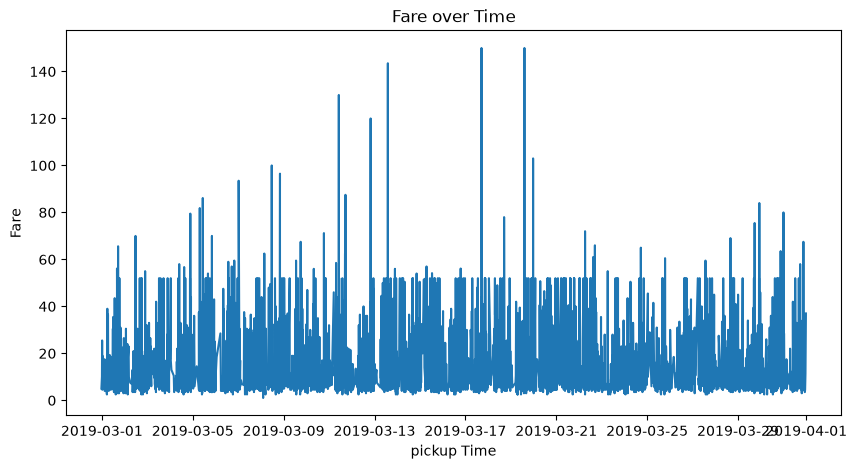

In [14]:
#3 matplotlib pandasplot
#linechart
import seaborn as sns 
import matplotlib.pyplot as plt
import pandas as pd
df = sns.load_dataset("taxis")
#converte pickup column to datetime
df["pickup"] = pd.to_datetime(df["pickup"])
#sort data by pickup time
df = df.sort_values("pickup")
#create line chart
plt.figure(figsize=(10,5))
plt.plot(df["pickup"],df["fare"])

plt.xlabel("pickup Time")
plt.ylabel("Fare")
plt.title("Fare over Time")

plt.show()

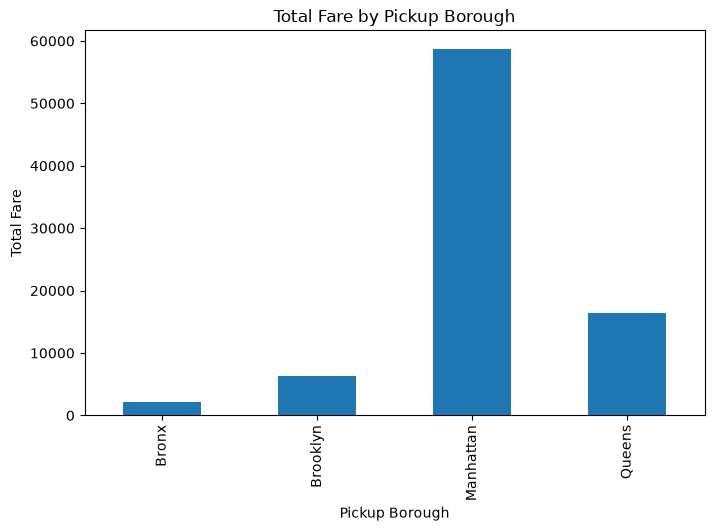

In [25]:
#3 bar chart
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

# Group data by pickup borough
borough_fare = df.groupby("pickup_borough")["fare"].sum()

# Create bar chart with colour
borough_fare.plot(kind="bar", figsize=(8, 5))

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")

plt.show()

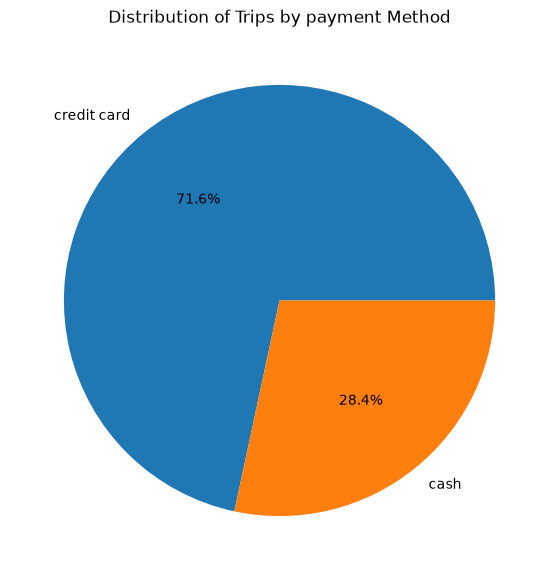

In [33]:
#pie chart
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

#count payment methods
payment_count =df["payment"].value_counts()
#create pie chart
plt.figure(figsize=(7,7))
plt.pie(
    payment_count,
    labels=payment_count.index,
    autopct="%1.1f%%"
)
plt.title("Distribution of Trips by payment Method")
plt.show()


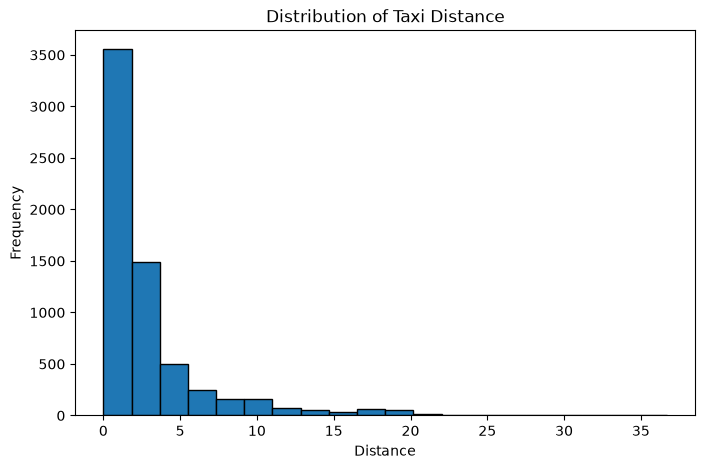

In [35]:
#Q3 histogram
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

# Create histogram
plt.figure(figsize=(8, 5))
plt.hist(df["distance"].dropna(), bins=20, edgecolor="black")

plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Taxi Distance")

plt.show()

<Figure size 900x500 with 0 Axes>

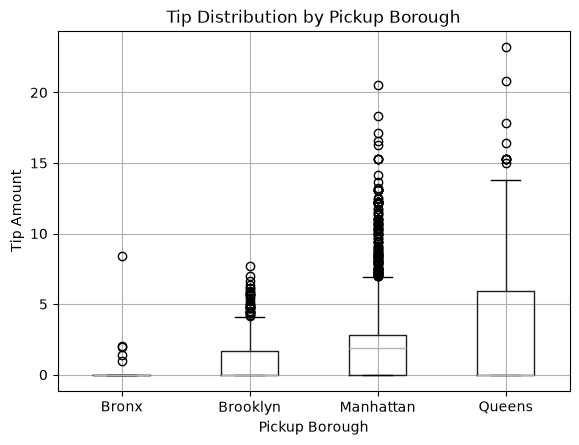

In [37]:
#4 box plot
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

# Create box plot
plt.figure(figsize=(9, 5))
df.boxplot(column="tip", by="pickup_borough")

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Tip Distribution by Pickup Borough")

plt.suptitle("")

plt.show()


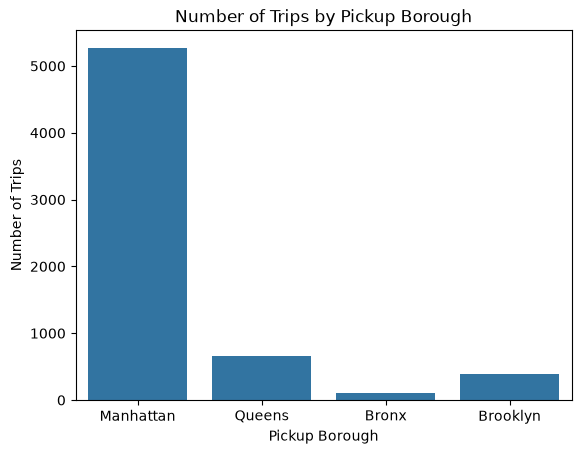

In [39]:
#4 visualizations using seaborn
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

# Create count plot
sns.countplot(data=df, x="pickup_borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Borough")

plt.show()

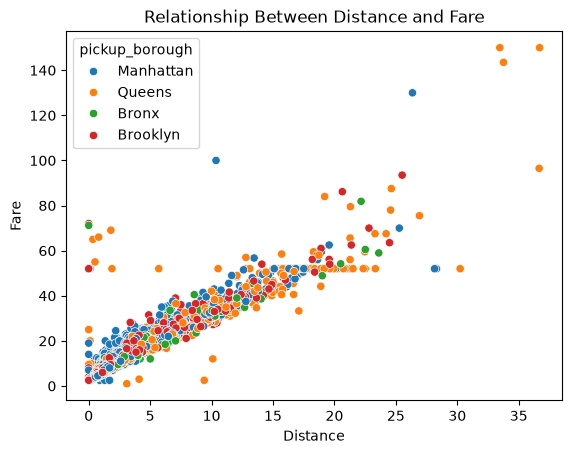

In [41]:
#4b scatter plot
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

# Create scatter plot
sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Relationship Between Distance and Fare")

plt.show()

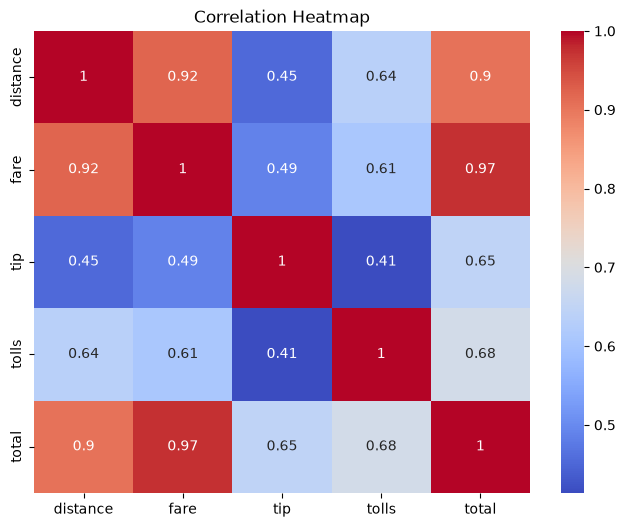

In [43]:
#4c heatmap
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

# Select numerical columns
numeric_data = df[
    ["distance", "fare", "tip", "tolls", "total"]
]

# Calculate correlation
correlation = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")

plt.show()

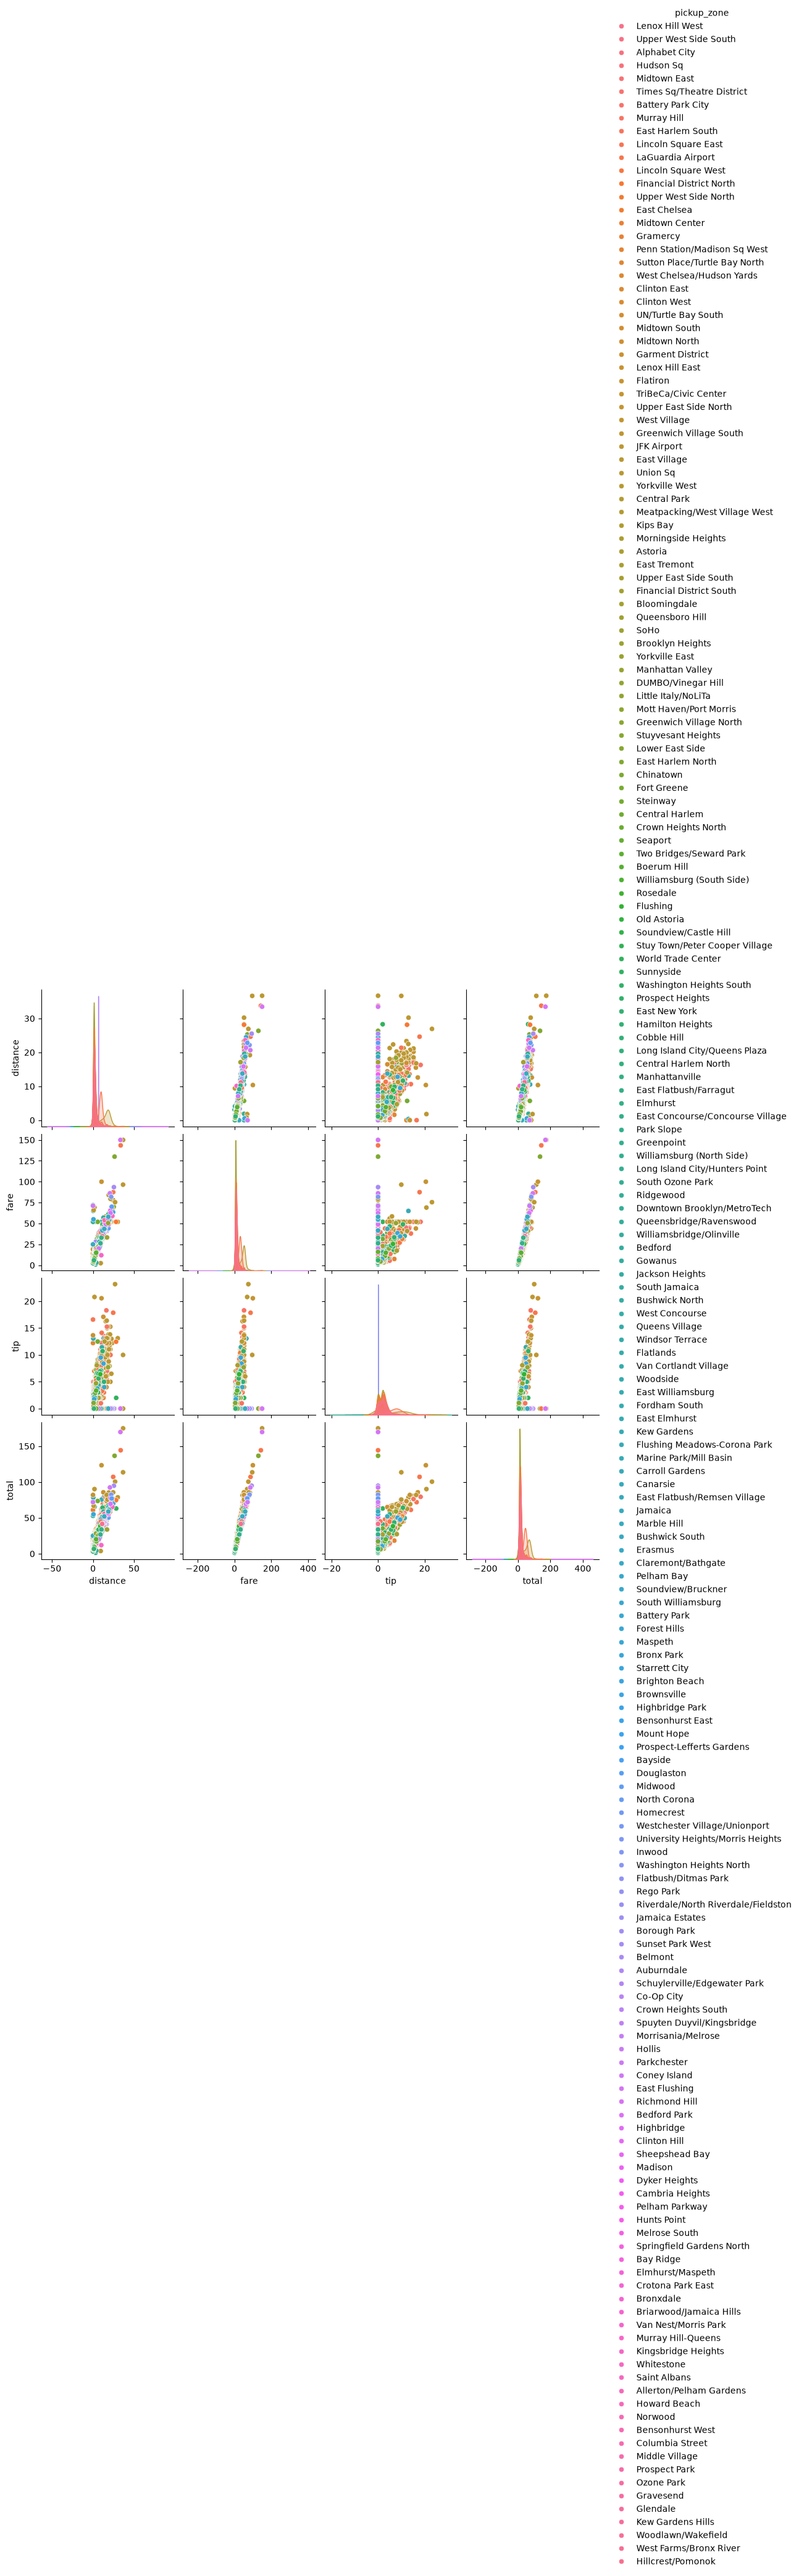

In [47]:
#4d pair plot
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

# Select required columns
pair_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()

# Create pair plot
sns.pairplot(
    pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone"
)

plt.show()

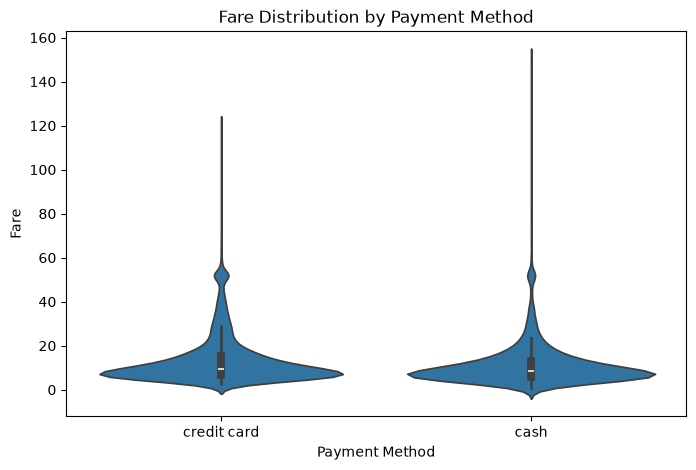

In [48]:
#4e violin plot
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

# Create violin plot
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution by Payment Method")

plt.show()